## Feature Engineering + Preprocessing

This notebook re-runs basic Data Wrangling & EDA and then performs feature engineering and preprocessing.

- Data Wrangling & EDA
  - Load dataset (one dataset)
  - Visualize distributions (histograms, boxplots, correlations)
  - Find missing values
  - Find outliers and typical checks
- Feature Engineering + Preprocessing
  - Encode categorical variables (One-Hot/Label)
  - Normalize/standardize features
  - Create derived features (text length, TF-IDF for text)


### 1) Load dataset & schema check


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid')

DATA_PATH = 'twitter_training.csv'
df = pd.read_csv(DATA_PATH, encoding='utf-8')

print('Shape:', df.shape)
df.head()


Shape: (74681, 4)


,2401,Borderlands,Positive,"im getting on borderlands and i will murder you all ,"
0,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
1,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
2,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
3,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
4,2401,Borderlands,Positive,im getting into borderlands and i can murder y...


In [2]:
# Schema info
print('Column dtypes:')
print(df.dtypes)
print('\nDescribe (numeric):')
display(df.describe())
print('\nDescribe (all):')
display(df.describe(include='all'))


Column dtypes:
2401                                                      int64
Borderlands                                              object
Positive                                                 object
im getting on borderlands and i will murder you all ,    object
dtype: object

Describe (numeric):


,2401
count,74681.000000
mean,6432.640149
std,3740.423819
min,1.000000
25%,3195.000000
50%,6422.000000
75%,9601.000000
max,13200.000000



Describe (all):


,2401,Borderlands,Positive,"im getting on borderlands and i will murder you all ,"
count,74681.000000,74681,74681,73995
unique,NaN,32,4,69490
top,NaN,Microsoft,Negative,"At the same time, despite the fact that there ..."
freq,NaN,2400,22542,172
mean,6432.640149,NaN,NaN,NaN
std,3740.423819,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN
25%,3195.000000,NaN,NaN,NaN
50%,6422.000000,NaN,NaN,NaN
75%,9601.000000,NaN,NaN,NaN


### 2) Normalize placeholders to NaN (text/categorical)


In [3]:
# Normalize placeholders to NaN
placeholders = {"", " ", "N/A", "NA", "None", "NULL", "Null", "null", "-", "--"}
obj_cols = df.select_dtypes(include=['object']).columns
for col in obj_cols:
    df[col] = df[col].astype(str).str.strip()
    df[col] = df[col].replace(list(placeholders), np.nan)
print('Placeholders normalized to NaN in object/text columns.')


Placeholders normalized to NaN in object/text columns.


### 3) Visualize distributions (histograms & boxplots)


Numeric columns: ['2401']
Object/Text columns: ['Borderlands', 'Positive', 'im getting on borderlands and i will murder you all ,']


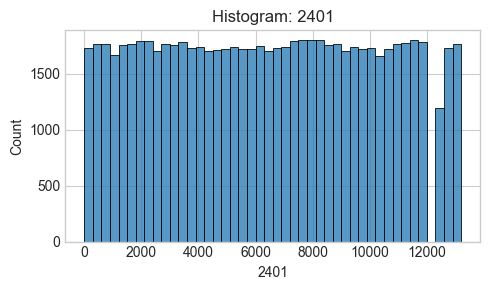

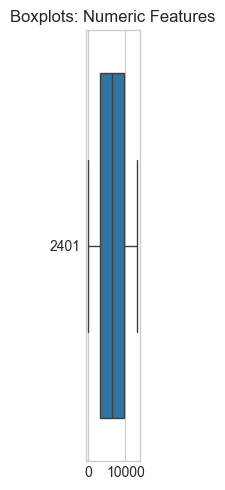

In [4]:
# Identify column types
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
object_cols = df.select_dtypes(include=['object']).columns.tolist()

print('Numeric columns:', numeric_cols)
print('Object/Text columns:', object_cols)

# Histograms for numeric columns
n = len(numeric_cols)
if n:
    ncols = min(3, max(1, n))
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*5, nrows*3))
    axes_list = list(np.ravel(axes)) if isinstance(axes, np.ndarray) else [axes]
    for i, col in enumerate(numeric_cols):
        ax = axes_list[i]
        sns.histplot(df[col].dropna(), kde=False, ax=ax)
        ax.set_title(f'Histogram: {col}')
    for j in range(n, len(axes_list)):
        axes_list[j].axis('off')
    plt.tight_layout(); plt.show()

# Boxplots for numeric columns
if n:
    plt.figure(figsize=(min(12, 1.2*len(numeric_cols)), 5))
    sns.boxplot(data=df[numeric_cols], orient='h')
    plt.title('Boxplots: Numeric Features')
    plt.tight_layout(); plt.show()


### 4) Correlations (numeric features)


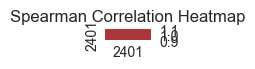

No highly correlated numeric pairs above threshold.


In [5]:
# Spearman heatmap and high-corr list
if numeric_cols:
    corr_s = df[numeric_cols].corr(method='spearman')
    plt.figure(figsize=(min(12, 1.2*len(numeric_cols)), min(10, 0.8*len(numeric_cols))))
    sns.heatmap(corr_s, cmap='vlag', center=0)
    plt.title('Spearman Correlation Heatmap')
    plt.tight_layout(); plt.show()

    corr_p = df[numeric_cols].corr(method='pearson')
    high_pairs = []
    for i, c1 in enumerate(numeric_cols):
        for j, c2 in enumerate(numeric_cols):
            if j <= i:
                continue
            r = corr_p.loc[c1, c2]
            if pd.notna(r) and abs(r) > 0.85:
                high_pairs.append((c1, c2, round(r, 3)))
    if high_pairs:
        print('Highly correlated pairs (pearson |r| > 0.85):')
        for a,b,r in sorted(high_pairs, key=lambda x: -abs(x[2])):
            print(f'- {a} vs {b}: r={r}')
    else:
        print('No highly correlated numeric pairs above threshold.')


### 5) Missing values and outliers


In [6]:
# Missingness
missing_per_col = df.isna().mean().sort_values(ascending=False)
print('Missing rate per column (%):')
display((missing_per_col * 100).round(2))

# Outliers (IQR)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
outlier_summary = []
for col in numeric_cols:
    s = df[col].dropna()
    if s.empty:
        continue
    q1, q3 = np.percentile(s, [25, 75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    cnt = int(((df[col] < lower) | (df[col] > upper)).sum())
    outlier_summary.append({'column': col, 'outlier_count': cnt})

print('\nOutlier counts per numeric column (IQR):')
display(pd.DataFrame(outlier_summary).sort_values('outlier_count', ascending=False))


Missing rate per column (%):


im getting on borderlands and i will murder you all ,    0.23
2401                                                     0.00
Borderlands                                              0.00
Positive                                                 0.00
dtype: float64


Outlier counts per numeric column (IQR):


,column,outlier_count
0,2401,0


### 6) Identify columns (target, text, categorical, numeric)


In [7]:
# Infer likely columns: [id, topic, label, text]
columns = df.columns.tolist()
print('Columns:', columns)

# Heuristic assignment based on position
if len(columns) >= 4:
    col_id, col_topic, col_label, col_text = columns[:4]
else:
    # Fallback names
    col_id, col_topic, col_label, col_text = (columns + [None, None, None, None])[:4]

print('Assumed columns -> id:', col_id, '| topic:', col_topic, '| label:', col_label, '| text:', col_text)

# Determine types
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
text_cols = [c for c in df.select_dtypes(include=['object']).columns.tolist() if c != col_label]
cat_cols = [col_topic] if col_topic in df.columns else []

print('Numeric:', numeric_cols)
print('Categorical:', cat_cols)
print('Text:', [col_text] if col_text in df.columns else [] )


Columns: ['2401', 'Borderlands', 'Positive', 'im getting on borderlands and i will murder you all ,']
Assumed columns -> id: 2401 | topic: Borderlands | label: Positive | text: im getting on borderlands and i will murder you all ,
Numeric: ['2401']
Categorical: ['Borderlands']
Text: ['im getting on borderlands and i will murder you all ,']


### 7) Encode categorical variables


In [10]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

encoded = {}

# Label encode the label column if present and object type
if col_label in df.columns and df[col_label].dtype == 'object':
    le = LabelEncoder()
    encoded['label'] = le.fit_transform(df[col_label].astype(str))
    label_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    print('Label mapping:', label_mapping)
else:
    encoded['label'] = df[col_label] if col_label in df.columns else None

# One-hot encode topic/category if present
if cat_cols:
    ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
    cat_array = ohe.fit_transform(df[cat_cols])
    cat_feature_names = ohe.get_feature_names_out(cat_cols)
    encoded['categorical'] = pd.DataFrame(cat_array, columns=cat_feature_names, index=df.index)
    print('Categorical one-hot shape:', encoded['categorical'].shape)
else:
    encoded['categorical'] = None


Label mapping: {'Irrelevant': np.int64(0), 'Negative': np.int64(1), 'Neutral': np.int64(2), 'Positive': np.int64(3)}
Categorical one-hot shape: (74681, 32)


### 8) Scale numeric features


In [11]:
from sklearn.preprocessing import StandardScaler, RobustScaler

num_cols_for_scaling = [c for c in df.select_dtypes(include=[np.number]).columns if c != col_label]

# Choose scaler (Robust handles outliers better). We'll compute both and keep Robust by default.
scaler_standard = StandardScaler()
scaler_robust = RobustScaler()

X_num_standard = scaler_standard.fit_transform(df[num_cols_for_scaling]) if num_cols_for_scaling else None
X_num_robust = scaler_robust.fit_transform(df[num_cols_for_scaling]) if num_cols_for_scaling else None

if num_cols_for_scaling:
    print('Scaled numeric (Standard) shape:', X_num_standard.shape)
    print('Scaled numeric (Robust) shape:', X_num_robust.shape)
else:
    print('No numeric columns to scale.')


Scaled numeric (Standard) shape: (74681, 1)
Scaled numeric (Robust) shape: (74681, 1)


### 9) Text-derived features and TF-IDF


In [13]:

from sklearn.feature_extraction.text import TfidfVectorizer
import re

# Use assumed text column
txt_col = col_text if col_text in df.columns else None

text_feats = {}
if txt_col:
    s = df[txt_col].fillna("").astype(str)
    # Derived features
    text_feats['len_chars'] = s.str.len()
    text_feats['len_words'] = s.str.split().str.len()
    text_feats['num_hashtags'] = s.str.count(r'#')
    text_feats['num_mentions'] = s.str.count(r'@')
    text_feats['num_urls'] = s.str.count(r'https?://|www\.')
    
    
    
print(text_feats)


{'len_chars': 0         51
1         50
2         51
3         57
4         53
        ... 
74676    128
74677    117
74678    125
74679    159
74680    119
Name: im getting on borderlands and i will murder you all ,, Length: 74681, dtype: int64, 'len_words': 0        12
1        10
2        10
3        12
4        10
         ..
74676    26
74677    23
74678    25
74679    32
74680    25
Name: im getting on borderlands and i will murder you all ,, Length: 74681, dtype: int64, 'num_hashtags': 0        0
1        0
2        0
3        0
4        0
        ..
74676    0
74677    0
74678    0
74679    0
74680    0
Name: im getting on borderlands and i will murder you all ,, Length: 74681, dtype: int64, 'num_mentions': 0        0
1        0
2        0
3        0
4        0
        ..
74676    0
74677    0
74678    0
74679    0
74680    0
Name: im getting on borderlands and i will murder you all ,, Length: 74681, dtype: int64, 'num_urls': 0        0
1        0
2        0
3        0
4       

In [14]:
# TF-IDF vectorization (unigram+bigram)
if txt_col:
    tfidf = TfidfVectorizer(ngram_range=(1,2), min_df=5, max_features=20000)
    X_tfidf = tfidf.fit_transform(df[txt_col].fillna('').astype(str))
    print('TF-IDF shape:', X_tfidf.shape)
    # Peek top features
    feature_names = np.array(tfidf.get_feature_names_out())
    print('Top TF-IDF terms sample:', feature_names[:20])
else:
    X_tfidf = None
    print('No text column found for TF-IDF.')


TF-IDF shape: (74681, 20000)
Top TF-IDF terms sample: ['00' '00 edt' '00 en' '000' '000 and' '00016' '00303' '01' '01 bes' '02'
 '02 home' '03' '04' '05' '05 19' '05 20' '06' '07' '07 20' '08']


### 10) Assemble features and sanity checks


In [15]:
# Combine numeric (robust scaled), categorical (one-hot), and text features

# Numeric
X_num = pd.DataFrame(X_num_robust, columns=num_cols_for_scaling, index=df.index) if isinstance(X_num_robust, np.ndarray) else None

# Categorical
X_cat = encoded['categorical'] if encoded.get('categorical') is not None else None

# Text-derived
X_text_basic = pd.DataFrame(text_feats) if text_feats else None

# Concatenate dense parts
parts = [p for p in [X_num, X_cat, X_text_basic] if p is not None]
X_dense = pd.concat(parts, axis=1) if parts else None

print('Dense feature matrix shape:', X_dense.shape if X_dense is not None else None)
print('TF-IDF sparse shape:', X_tfidf.shape if X_tfidf is not None else None)

# Sanity checks
if X_dense is not None:
    print('Any NaNs in dense features:', X_dense.isna().any().any())
    display(X_dense.head())


Dense feature matrix shape: (74681, 38)
TF-IDF sparse shape: (74681, 20000)
Any NaNs in dense features: False


,2401,Borderlands_Amazon,Borderlands_ApexLegends,Borderlands_AssassinsCreed,Borderlands_Battlefield,Borderlands_Borderlands,Borderlands_CS-GO,Borderlands_CallOfDuty,Borderlands_CallOfDutyBlackopsColdWar,Borderlands_Cyberpunk2077,Borderlands_Dota2,Borderlands_FIFA,Borderlands_Facebook,Borderlands_Fortnite,Borderlands_Google,Borderlands_GrandTheftAuto(GTA),Borderlands_Hearthstone,Borderlands_HomeDepot,Borderlands_LeagueOfLegends,Borderlands_MaddenNFL,Borderlands_Microsoft,Borderlands_NBA2K,Borderlands_Nvidia,Borderlands_Overwatch,Borderlands_PlayStation5(PS5),Borderlands_PlayerUnknownsBattlegrounds(PUBG),Borderlands_RedDeadRedemption(RDR),Borderlands_TomClancysGhostRecon,Borderlands_TomClancysRainbowSix,Borderlands_Verizon,Borderlands_WorldOfCraft,Borderlands_Xbox(Xseries),Borderlands_johnson&johnson,len_chars,len_words,num_hashtags,num_mentions,num_urls
0,-0.627693,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,51,12,0,0,0
1,-0.627693,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,50,10,0,0,0
2,-0.627693,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,51,10,0,0,0
3,-0.627693,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,57,12,0,0,0
4,-0.627693,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,53,10,0,0,0


### 11) Findings and notes

- Encodings applied: label (if string), one-hot for topic (if present)
- Scaling used: RobustScaler for numeric (also computed StandardScaler for reference)
- Text features: length, counts (#, @, URLs), TF-IDF (1–2 grams, min_df=5)
- Next steps (optional): model training with proper train/valid split; fit transformers on train only
